## Machine Learning Notebook Week-2

### Table of Contents


##### 1. Classification Analysis
##### 2. Logistic Regression
##### 3. Classification Metrics  
##### 4. Data Imbalance (Stratified Analysis & SMOTE Analysis)
##### 5. KNN Regressor
##### 6. KNN Classifier
##### 7. Gaussian Naive Bayes Algorithm
##### 8. Decision Tree Regressor
##### 9. Decision Tree Classifier

##### Classification Analysis

Classification Analysis is a machine learning technique used to predict a category or class label for given input data.
It helps in dividing data into predefined groups based on patterns learned from labeled examples during training.

In simple words:
Classification is used when we want to predict categories — like yes/no, spam/not spam, or types of animals — instead of numbers.

#### Logistic Regression

It determines the relationship between the input features (X) and a categorical dependent variable (y), where the goal is to classify observations into distinct groups or categories.
It is also known as, Logistic Regression (for binary classification).
The mathematical form of the Logistic (Sigmoid) Function is given as:

<p style='text-indent:25em'> <strong> P(y=1) = 1 / (1 + e<sup>-(β<sub>0</sub> + β<sub>1</sub>x)</sup>) </strong> </p>

where,

y = Dependent variable (categorical: e.g., 0 or 1) <br>
x = Independent variable <br>
β<sub>0</sub> = Intercept term <br>
β<sub>1</sub> = Coefficient of the independent variable <br>
e = Base of the natural logarithm <br>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
##### We will use loan default dataset

###### Data Dictionary

| **Column Name**       | **Data Type**        | **Description**                                                                          | **Example Values** |
| --------------------- | -------------------- | ---------------------------------------------------------------------------------------- | ------------------ |
| **Loan_Default**      | Categorical (Yes/No) | Indicates whether the customer defaulted on the loan.                                    | Yes, No            |
| **Cbill_Score**       | Numeric (Integer)    | Customer’s credit score ranging between 300–900. Higher scores imply lower default risk. | 576, 785, 689      |
| **Gender**            | Categorical          | Gender of the applicant.                                                                 | Male, Female       |
| **Occupation**        | Categorical          | Primary source of employment or income.                                                  | Business, Job      |
| **Loan_Amount_Lakhs** | Numeric (Float)      | Loan amount sanctioned to the customer (in Lakhs).                                       | 7.03, 11.83, 18.10 |
| **Dependent**         | Categorical          | Indicates whether the applicant has financial dependents.                                | Yes, No            |
| **Age**               | Numeric (Integer)    | Age of the applicant in years.                                                           | 23, 47, 50         |
| **Income**            | Categorical          | Applicant’s income level based on financial profile.                                     | Low, Medium, High  |


In [ ]:
df = pd.read_csv('/content/loan_default.csv')
df.head()

,Loan_Default,Cbill_Score,Gender,Occupation,Loan_Amount_Lakhs,Dependent,Age,Income
0,No,576,Male,Job,18.10,Yes,23,Low
1,No,663,Female,Job,11.03,Yes,27,Medium
2,Yes,689,Male,Business,11.83,No,49,Medium
3,No,785,Male,Job,7.03,No,50,High
4,Yes,661,Male,Job,9.29,No,47,Medium


##### Model Pre-Processing

###### Before Model Building 2 important/Mandatory things to check

###### 1. No Missing values

###### 2. No String/categorical data

###### Handling Missing Values

In [ ]:
df.isnull().sum()

,0
Loan_Default,0
Cbill_Score,0
Gender,0
Occupation,0
Loan_Amount_Lakhs,0
Dependent,0
Age,0
Income,0


###### Handling Categorical Data using Encoding techniques

In [ ]:
df_num=df.select_dtypes(include=np.number)
df_cat=df.select_dtypes(exclude=np.number)

In [ ]:
df_num.head(1)

,Cbill_Score,Loan_Amount_Lakhs,Age
0,576,18.1,23


In [ ]:
df_cat.head(1)

,Loan_Default,Gender,Occupation,Dependent,Income
0,No,Male,Job,Yes,Low


In [ ]:
df_cat.drop(columns=['Loan_Default'],inplace=True)


In [ ]:
encoded_data=pd.get_dummies(df_cat,dtype='int',drop_first=True)

In [ ]:
final_data=pd.concat([df_num,encoded_data,df[["Loan_Default"]]],axis=1)

In [ ]:
final_data.head()

,Cbill_Score,Loan_Amount_Lakhs,Age,Gender_Male,Occupation_Job,Dependent_Yes,Income_Low,Income_Medium,Loan_Default
0,576,18.10,23,1,1,1,1,0,No
1,663,11.03,27,0,1,1,0,1,No
2,689,11.83,49,1,0,0,0,1,Yes
3,785,7.03,50,1,1,0,0,0,No
4,661,9.29,47,1,1,0,0,1,Yes


In [ ]:
from sklearn.model_selection import train_test_split
x=final_data.drop(columns='Loan_Default')
y=final_data['Loan_Default']
xtrain,xtest,ytrain,ytest=train_test_split(x,y,train_size=0.7,random_state=133)

##### SKLEARN Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression


In [ ]:
log_reg=LogisticRegression(max_iter=1000)
log_reg.fit(xtrain,ytrain)
y_pred=log_reg.predict(xtest)

In [ ]:
y_prob=log_reg.predict_proba(xtest)[:,1]

In [ ]:
#y_prob

In [ ]:
predictions=pd.DataFrame({'Predicted':y_pred})
#predictions.head()
predictions.value_counts()


,count
Predicted,
No,294
Yes,6


##### Model Evaluation

###### Accuracy Score

In [ ]:
from sklearn.metrics import classification_report,roc_auc_score,roc_curve,confusion_matrix

###### Confusion matrix

In [ ]:
cm=confusion_matrix(ytest,y_pred)
cm

array([[238,   5],
       [ 56,   1]])

In [ ]:
TN=cm[0,0]
FP=cm[0,1]
FN=cm[1,0]
TP=cm[1,1]

In [ ]:
#accuracy
accuracy=(TP+TN)/(TP+TN+FP+FN)
accuracy

np.float64(0.7966666666666666)

###### Precision, Recall & F1 Score

In [ ]:
pression_0=TN/(TN+FN)
print('pression_0:',pression_0)
pression_1=TP/(TP+FP)
print('pression_1:',pression_1)
#recall
recall_0=TN/(TN+FP)
print('recall_0:',recall_0)
recall_1=TP/(TP+FN)
print('recall_1:',recall_1)
#f1_score
f1_score_0=2*pression_0*recall_0/(pression_0+recall_0)
f1_score_1=2*pression_1*recall_1/(pression_1+recall_1)
print('f1_score_0:',f1_score_0)
print('f1_score_1:',f1_score_1)

pression_0: 0.8095238095238095
pression_1: 0.16666666666666666
recall_0: 0.9794238683127572
recall_1: 0.017543859649122806
f1_score_0: 0.8864059590316573
f1_score_1: 0.031746031746031744


In [ ]:
report=classification_report(ytest,y_pred)
print(report)

              precision    recall  f1-score   support

          No       0.81      0.98      0.89       243
         Yes       0.17      0.02      0.03        57

    accuracy                           0.80       300
   macro avg       0.49      0.50      0.46       300
weighted avg       0.69      0.80      0.72       300



###### ROC AUC Score

In [ ]:
ytest_enc=ytest.replace(to_replace=['Yes','No'],value=[1,0])

/tmp/ipykernel_2004/1733775964.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ytest_enc=ytest.replace(to_replace=['Yes','No'],value=[1,0])


In [ ]:
y_pred_enc=pd.Series(y_pred).replace(to_replace=['Yes','No'],value=[1,0])

/tmp/ipykernel_2004/197645936.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_pred_enc=pd.Series(y_pred).replace(to_replace=['Yes','No'],value=[1,0])


In [ ]:
roc_auc_score(ytest_enc,y_prob)

np.float64(0.5954082737708469)

In [ ]:
#now to plot the roc auc graph we need TPR value and FPR values for different threshold and in order
#to get these values we use roc_curve function but roc_curve needs probability

fpr,tpr,thresholds=roc_curve(ytest_enc,y_prob)

In [ ]:
thresholeds_tpr_fpr=pd.DataFrame({'Threshold':thresholds,'TPR':tpr,'FPR':fpr})
thresholeds_tpr_fpr.head()

,Threshold,TPR,FPR
0,inf,0.000000,0.000000
1,0.598638,0.000000,0.004115
2,0.541984,0.017544,0.004115
3,0.474245,0.017544,0.041152
4,0.449155,0.070175,0.041152


###### ROC AUC Curve

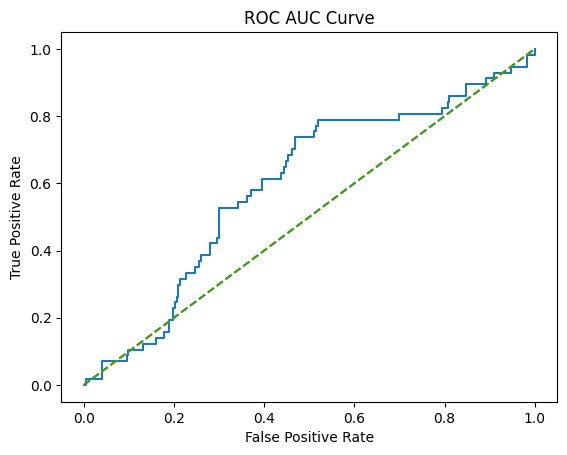

In [ ]:
plt.plot(fpr,tpr)
plt.plot([[0,0],[1,1]],linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC AUC Curve')
plt.show()

##### Data Imabalance

In [ ]:
xtrain.shape

(700, 8)

In [ ]:
ytest.shape

(300,)

In [ ]:
final_data.head()

,Cbill_Score,Loan_Amount_Lakhs,Age,Gender_Male,Occupation_Job,Dependent_Yes,Income_Low,Income_Medium,Loan_Default
0,576,18.10,23,1,1,1,1,0,No
1,663,11.03,27,0,1,1,0,1,No
2,689,11.83,49,1,0,0,0,1,Yes
3,785,7.03,50,1,1,0,0,0,No
4,661,9.29,47,1,1,0,0,1,Yes


In [ ]:
x=final_data.drop(columns='Loan_Default')
y=final_data['Loan_Default']
xtrain,xtest,ytrain,ytest=train_test_split(x,y,train_size=0.7,random_state=133)

##### SMOTE Analysis

In [ ]:
final_data["Loan_Default"].value_counts()

,count
Loan_Default,
No,800
Yes,200


In [ ]:
# we can see thre is a huge imabalcne in the target variable, so this is reason for getting poor model performance.

# When Performing SMOTE analysis we need to keep in mind regarding Data Leakage.
# Basically when you are building model and evaluating the it the test data which we use to evaluate the model should be completley
# unseen.
# Scaling ---> SS---- )(x-mu)/sigma ---> here mu & sigma are the statistical parameters.

#df ---> Scaling mu & sigma on df.

# scaled_df ---> train & test ---> Wrong

#Split the data
# Train ----> mu&sigma ----> scaled_xtrain using fit_transform.
# Test ----> Here we will never know the testing parameters becuase in the deployment its
#not possible to find the everydays model prediction parameters
# we will use the training parameters (mu & sigma) to scale the testing data.
# we will use only transform.


# final_df ---> imbalance ---> smote ---> train &  test.
# are we testinf the model on the original data or the synthetic balanced data.

# final_df ----> SPLIT ---> Train & Test ---> Smote__> Train and directly evaluate the model using test data without smote

In [ ]:
ytrain.value_counts()

,count
Loan_Default,
No,557
Yes,143


In [ ]:
ytrain.value_counts(normalize=True)*100

#SMOTE is a oversampling Technique---> Increase the Minority class
#80:20-->50:50worng-->70:30/65:35

,proportion
Loan_Default,
No,79.571429
Yes,20.428571


In [ ]:
from imblearn.over_sampling import SMOTE
smote=SMOTE(sampling_strategy={'Yes':250,'No':560},k_neighbors=4,random_state=100)
smote_xtrain,smote_ytrain=smote.fit_resample(xtrain,ytrain)

In [ ]:
# now we will use the new smote train data to fit the model
# we can apply any alogorithm of our choice on SMOTE data.

In [ ]:
lr_smote=LogisticRegression(max_iter=1000)
lr_smote.fit(smote_xtrain,smote_ytrain)
y_pred_smote=lr_smote.predict(xtest)
print(classification_report(ytest,y_pred_smote))

              precision    recall  f1-score   support

          No       0.81      0.88      0.85       243
         Yes       0.22      0.14      0.17        57

    accuracy                           0.74       300
   macro avg       0.51      0.51      0.51       300
weighted avg       0.70      0.74      0.72       300



#### K- Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a simple, instance-based machine learning algorithm used for classification and regression.
It predicts the output for a new data point based on the majority class (for classification) or average value (for regression) of its k nearest data points in the training set.

In simple words:
KNN looks at the “k” closest examples in the dataset and decides the output based on what most of those neighbors say.

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/Salary.csv')
cat_data = df.select_dtypes(exclude = np.number)
num_data = df.select_dtypes(include = np.number)
encoded_cat_data = pd.get_dummies(cat_data,drop_first=True,dtype='int')
final_df = pd.concat([num_data,encoded_cat_data],axis=1)
x = final_df.drop(columns='Salary_Rupees')
y = final_df['Salary_Rupees']
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.7,test_size=0.3)

In [ ]:
final_df.head()

,Experience,Age,Height_cm,Weight_kg,Salary_Rupees,Gender_Male,Designation_Manager,Designation_Senior Manager,Education_UG
0,6,37,161.4,81.8,97634.09,0,0,0,1
1,19,47,170.1,61.1,150705.15,1,0,0,1
2,28,59,168.2,44.1,221352.13,0,1,0,0
3,14,38,164.7,73.1,132014.12,1,0,0,0
4,10,33,164.4,81.9,127330.77,1,0,1,1


##### KNN Regressor

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
knn_reg=KNeighborsRegressor()
knn_reg.fit(x_train,y_train)
knn_pred=knn_reg.predict(x_test)

##### Model Evaluation

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error
print('MAPE:',mean_absolute_percentage_error(y_test,knn_pred))

MAPE: 0.08814029485939331


In [ ]:
knn_reg_weighted=KNeighborsRegressor(weights='distance',n_neighbors=3,p=2)
knn_reg_weighted.fit(x_train,y_train)
knn_pred_weighted=knn_reg_weighted.predict(x_test)

In [ ]:
#model evalution
print('MAPE:',mean_absolute_percentage_error(y_test,knn_pred_weighted))

MAPE: 0.08646356817987035


##### KNN Classifier

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn_clf=KNeighborsClassifier()
knn_clf.fit(xtrain,ytrain)
knn_clf_pred=knn_clf.predict(xtest)

##### Model Evaluation

In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,f1_score

#print('Confusion Matrix:\n',confusion_matrix(ytest,knn_clf_pred))
print('Classification Report:\n',classification_report(ytest,knn_clf_pred))

Classification Report:
               precision    recall  f1-score   support

          No       0.81      0.88      0.84       243
         Yes       0.19      0.12      0.15        57

    accuracy                           0.74       300
   macro avg       0.50      0.50      0.50       300
weighted avg       0.69      0.74      0.71       300



In [ ]:
#weighted knn classifier
knn_clf_weighted=KNeighborsClassifier(weights='distance',n_neighbors=3,p=1)
knn_clf_weighted.fit(xtrain,ytrain)
knn_clf_pred_weighted=knn_clf_weighted.predict(xtest)

In [ ]:
print("classification report:",classification_report(ytest,knn_clf_pred_weighted))
print("accuracy score:",accuracy_score(ytest,knn_clf_pred_weighted))

classification report:               precision    recall  f1-score   support

          No       0.82      0.82      0.82       243
         Yes       0.23      0.23      0.23        57

    accuracy                           0.71       300
   macro avg       0.53      0.53      0.53       300
weighted avg       0.71      0.71      0.71       300

accuracy score: 0.71


##### Hypertuned Model using Grid Search

In [ ]:
from sklearn.model_selection import GridSearchCV
parameters={'n_neighbors':[3,4,5,6,7],'p':[1,2,3],'weights':['uniform','distance']}
knn_classifier=KNeighborsClassifier()
clf=GridSearchCV(knn_classifier,parameters,cv=3,n_jobs=-1)
clf.fit(x,y)


GridSearchCV(cv=3, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': [3, 4, 5, 6, 7], 'p': [1, 2, 3],
                         'weights': ['uniform', 'distance']})

In [ ]:
clf.best_params_


{'n_neighbors': 4, 'p': 1, 'weights': 'uniform'}

##### KNN Tuned Model

In [ ]:
clf.fit(x,y)

GridSearchCV(cv=3, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': [3, 4, 5, 6, 7], 'p': [1, 2, 3],
                         'weights': ['uniform', 'distance']})

##### Gaussina Naive Bayes Algorithm

Gaussian Naïve Bayes is a probabilistic classification algorithm based on Bayes’ Theorem, which assumes that the features (independent variables) are independent of each other and follow a normal (Gaussian) distribution.
It calculates the probability of each class for a given data point and assigns the class with the highest probability as the prediction.

In simple words:
Gaussian Naïve Bayes predicts a category by using probability — it assumes each feature contributes independently and that data is normally distributed.

##### GNB Model

In [ ]:
from sklearn.naive_bayes import GaussianNB
gnb=GaussianNB()
gnb.fit(xtrain,ytrain)
gnb_pred=gnb.predict(xtest)

In [ ]:
gnb_pred_proba=gnb.predict_proba(xtest)[:,1]

##### Model Evaluation

In [ ]:
from sklearn.metrics import classification_report,f1_score,roc_auc_score,roc_curve, confusion_matrix
#import pandas as pd

# Encode gnb_pred to numerical labels (0 and 1) to match ytest_enc
#gnb_pred_enc = pd.Series(gnb_pred).replace(to_replace=['Yes','No'],value=[1,0])

#print('ROC AUC Score:',roc_auc_score(ytest_enc,gnb_pred_proba))

print('Confusion Matrix:\n',confusion_matrix(ytest,gnb_pred))
print('Classification Report:\n',classification_report(ytest,gnb_pred))

Confusion Matrix:
 [[180  63]
 [ 34  23]]
Classification Report:
               precision    recall  f1-score   support

          No       0.84      0.74      0.79       243
         Yes       0.27      0.40      0.32        57

    accuracy                           0.68       300
   macro avg       0.55      0.57      0.55       300
weighted avg       0.73      0.68      0.70       300



##### CART Models

CART stands for Classification and Regression Tree.
It is a decision tree-based algorithm used for both classification (predicting categories) and regression (predicting continuous values).
The model works by splitting the data into smaller subsets based on feature values, creating a tree-like structure of decisions that lead to a prediction.

##### Decision Tree

A Decision Tree is a model that makes decisions by following a flow of questions (conditions) about the input features.
Each internal node represents a feature test, each branch represents an outcome of that test, and each leaf node represents a final decision or prediction.
The algorithm selects the best feature to split the data using metrics like Gini Index or Information Gain.

In simple words:
A Decision Tree works like a flowchart — it splits the data step by step to make a final decision.

##### Decision Tree Regressor

In [ ]:
from sklearn.tree import DecisionTreeRegressor
DT_REG=DecisionTreeRegressor()
DT_REG.fit(x_train,y_train)
DT_REG_pred=DT_REG.predict(x_test)

##### Model Evaluation

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error
print('MAPE:',mean_absolute_percentage_error(y_test,DT_REG_pred))

MAPE: 0.09258299167522856


##### Decision Tree Classifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier
DT_clf=DecisionTreeClassifier()
DT_clf.fit(xtrain,ytrain)
DT_clf_pred=DT_REG.predict(xtest)

##### Model Evaluation

In [ ]:

from sklearn.metrics import classification_report
print(classification_report(ytest,DT_clf_pred))

              precision    recall  f1-score   support

          No       0.82      0.76      0.79       243
         Yes       0.22      0.28      0.24        57

    accuracy                           0.67       300
   macro avg       0.52      0.52      0.52       300
weighted avg       0.70      0.67      0.69       300



##### Hyperparameter tuning
##### Decision tree Tuned Model

In [ ]:
#we can perform hyperparameter tununing

In [ ]:
from sklearn.model_selection import GridSearchCV
DT_clf=DecisionTreeClassifier()
parameters={'criterion':['gini','entropy'],'max_depth':[2,3,4,5],'max_features':[2,3,4,5,6,7],'max_leaf_nodes':[2,3,4]}
dt_clf=GridSearchCV(DT_clf,parameters,cv=3,n_jobs=-1)
dt_clf.fit(x,y)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [2, 3, 4, 5],
                         'max_features': [2, 3, 4, 5, 6, 7],
                         'max_leaf_nodes': [2, 3, 4]})

##### Model Evaluation

In [ ]:
dt_clf.best_params_

{'criterion': 'gini', 'max_depth': 2, 'max_features': 3, 'max_leaf_nodes': 4}

In [ ]:
from sklearn.tree import DecisionTreeClassifier
DT_clf=DecisionTreeClassifier(criterion='gini', max_depth=2, max_features=3, max_leaf_nodes=4)
DT_clf.fit(xtrain,ytrain)
DT_clf_pred=DT_REG.predict(xtest)

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(ytest,DT_clf_pred))

              precision    recall  f1-score   support

          No       0.82      0.76      0.79       243
         Yes       0.22      0.28      0.24        57

    accuracy                           0.67       300
   macro avg       0.52      0.52      0.52       300
weighted avg       0.70      0.67      0.69       300



In [ ]:
dt_tuned=DecisionTreeClassifier(criterion='gini', max_depth=2, max_features=3, max_leaf_nodes=3)
dt_tuned.fit(xtrain,ytrain)

DecisionTreeClassifier(max_depth=2, max_features=3, max_leaf_nodes=3)

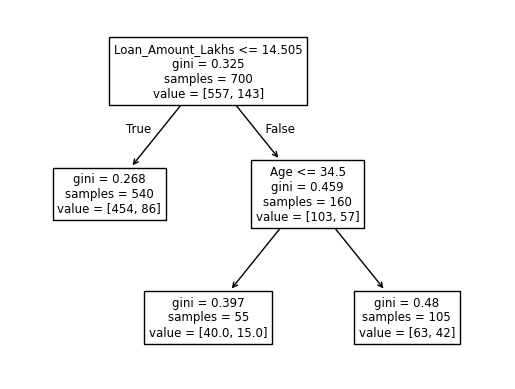

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plot_tree(dt_tuned,feature_names=x.columns)
plt.show()